# 05 — Causal intervention: is the truth direction the *lever*, or just a correlate? (MM vs LR)

Exp 4 showed θ_truth is **correlated** with truth (0.97 AUROC). That is not the
same as the model *using* it. This experiment is the causal test (M&T §6):

> Push activations along θ at L20 and measure whether the model's **own truth
> judgment** moves. If it does → the direction is a causal lever. If not → it was
> a correlate.

And the headline M&T comparison — the reason we kept both probes:

> θ_LR and θ_MM have ~identical AUROC (0.969 vs 0.968). Do they differ in *causal*
> effect? M&T: **MM moves behavior more than LR at matched strength**, because LR's
> max-margin tilt finds a good *boundary* while MM points at the actual *feature*.

## How it works (logit-NIE, single forward pass — NOT generation)

1. **Behavioral readout** (independent of the probe, so it isn't circular): put each
   statement in a true/false-eliciting prompt and read
   `Δ = logP("True") − logP("False")` at the answer position. True statements →
   Δ⁺ > 0; false → Δ⁻ < 0.
2. **Intervene** on a *false* statement: add `k·θ` to the residual at L20 across the
   context tokens (NOT the readout position — `mode='context'`). Re-read Δ → Δ\*⁻.
3. **NIE** = (Δ\*⁻ − Δ⁻) / (Δ⁺ − Δ⁻). 0 = inert; 1 = false now reads as true as a
   genuine true statement.
4. **Compare** θ_LR vs θ_MM at **matched strength** (`lib.matched_steering_vector`:
   k=1 = one true−false gap along each probe's own readout), sweep k, plot NIE(k).
   Optional negative control: the Exp 1 **SP direction** → expect NIE ≈ 0.

The steering vector is added by `lib.steering` (a forward hook on
`model.model.layers[20]` — the write-side mirror of `collect_activations`).

> **⚠️ `lib.steering` is a `TODO_PETER` stub — implement it first.** It's the one
> real gear in Exp 5 (the causal intervention itself). Until it's written, the NIE
> cells below will raise `NotImplementedError`. Verify your implementation with the
> **steering tests in `sandbox.ipynb`**, then run this notebook.

## Predictions — write BEFORE running

**Peter:** MM ≥ LR on NIE — probably MM a bit higher (M&T found it), but the two
start from ~identical AUROC so they could also tie. **Not expecting anything
drastic.** Baseline must separate (Δ⁺ > Δ⁻) or NIE is undefined.

**Claude:** MM > LR is the modal M&T outcome and I'd bet on it qualitatively, but at
0.968≈0.969 AUROC and L20 (late-ish, near where features get consumed) the gap may
be modest. SP-direction control ≈ 0. NIE at matched k=1 likely < 0.5 (one gap of
probe-readout ≠ one gap of behavior); needs k>1 to approach 1.

_Your final prediction:_
-

In [1]:
get_ipython().run_line_magic('load_ext', 'autoreload')
get_ipython().run_line_magic('autoreload', '2')

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import lib
from lib import DATA_DIR

LAYER = 20
SEED = 0

## Directions + matched-strength steering vectors

Reuse the **4a truth directions** (statement-summarization position, the feature we
validated in 4b). Refit LR+MM from the 4a cache, take θ_LR = `lr.coef_`, θ_MM = the
MM direction, and the class means μ⁺/μ⁻ for normalization. `matched_steering_vector`
scales each so k=1 = one true−false gap along that probe's readout.

In [2]:
assert lib.cache_exists("truth_layer20"), "Run Exp 4a first (it caches truth_layer20)."
tb = lib.load_cache("truth_layer20")
X_tr = tb['X_train_last'].float().numpy()
y_tr = tb['y_train'].numpy()

lr = lib.fit_lr_probe(X_tr, y_tr)
theta_lr = lr.coef_[0]
theta_mm = lib.mm_direction(X_tr, y_tr)

mu_pos = X_tr[y_tr == 1].mean(0)
mu_neg = X_tr[y_tr == 0].mean(0)

v_lr = lib.matched_steering_vector(theta_lr, mu_pos, mu_neg)
v_mm = lib.matched_steering_vector(theta_mm, mu_pos, mu_neg)
print(f"|v_lr| = {np.linalg.norm(v_lr):.2f}   |v_mm| = {np.linalg.norm(v_mm):.2f}")
print(f"cos(theta_lr, theta_mm) = {theta_lr@theta_mm/(np.linalg.norm(theta_lr)*np.linalg.norm(theta_mm)):.3f}")
print("(both normalized to one true-false readout-gap; |v| differs because the directions differ)")

|v_lr| = 6.07   |v_mm| = 17.82
cos(theta_lr, theta_mm) = 0.341
(both normalized to one true-false readout-gap; |v| differs because the directions differ)


## Load model + the behavioral readout, with a baseline sanity gate

**Gate:** the model's own True/False judgment must separate true from false
statements (Δ⁺ > Δ⁻, AUROC ≫ 0.5). If it doesn't, the model isn't expressing truth
in its output here and NIE is meaningless — stop and rethink the readout format
before trusting any intervention number.

In [3]:
model, tok = lib.load_model_and_tokenizer()
true_ids, false_ids = lib.truth_token_ids(tok)

# 4a test statements (rebuild for the strings), split by truth
train, test = lib.build_truth_dataset(DATA_DIR / "facts_true_false.csv", seed=SEED, n_train=400, n_test=150)
stmt_true  = [r['statement'] for r in test if r['label'] == 1]
stmt_false = [r['statement'] for r in test if r['label'] == 0]
eval_true  = [lib._make_eval_prompt(s) for s in stmt_true]
eval_false = [lib._make_eval_prompt(s) for s in stmt_false]

d_pos = lib.truth_logit_diff(model, tok, eval_true,  true_ids, false_ids)
d_neg = lib.truth_logit_diff(model, tok, eval_false, true_ids, false_ids)
PDpos, PDneg = float(d_pos.mean()), float(d_neg.mean())

all_d = np.concatenate([d_pos, d_neg])
all_y = np.array([1]*len(d_pos) + [0]*len(d_neg))
print(f"baseline Δ (logP True - logP False):  true stmts = {PDpos:+.2f},  false stmts = {PDneg:+.2f}")
print(f"behavioral AUROC (model's own judgment separates true/false): {lib.auroc(all_d, all_y):.3f}")
assert PDpos > PDneg, "GATE FAILED: model doesn't rate true statements as more true. NIE undefined."
print("GATE PASSED — proceed to intervention." if PDpos > PDneg else "")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

baseline Δ (logP True - logP False):  true stmts = +17.47,  false stmts = -19.13
behavioral AUROC (model's own judgment separates true/false): 0.987
GATE PASSED — proceed to intervention.


## NIE sweep — θ_LR vs θ_MM (+ SP-direction control)

For each k, steer **false** statements along the (matched) vector and recompute Δ.
NIE = (Δ\*⁻ − Δ⁻)/(Δ⁺ − Δ⁻). The SP control loads the Exp 1 probe direction and
should sit near 0 (steering the *persona* axis shouldn't change truth behavior).

In [4]:
# Steering is potent here: matched-v is one readout-gap PER POSITION, and mode='context'
# adds it to all ~25 context tokens — so the clean (non-destructive) regime is at small k.
# Sample fine and low; if NIE is still rising at k=4, extend upward.
KS = [0, 0.25, 0.5, 1, 1.5, 2, 3, 4]

def nie_curve(v, label):
    out = []
    for k in KS:
        if k == 0:
            dk = d_neg
        else:
            dk = lib.truth_logit_diff(model, tok, eval_false, true_ids, false_ids,
                                      steer=dict(layer=LAYER, vector=v, coeff=float(k), mode='context'))
        out.append((dk.mean() - PDneg) / (PDpos - PDneg))
    print(f"  {label}: " + "  ".join(f"k={k}:{n:+.2f}" for k, n in zip(KS, out)))
    return out

print("NIE(k):")
nie = {'LR (theta_lr)': nie_curve(v_lr, 'LR'),
       'MM (theta_mm)': nie_curve(v_mm, 'MM')}

# Optional negative control: Exp 1 SP-probe direction, expect NIE ~ 0.
if lib.cache_exists("sanity_layer20"):
    sb = lib.load_cache("sanity_layer20")
    Xsp, ysp = sb['X_train'].float().numpy(), sb['y_train'].numpy()
    sp_lr = lib.fit_lr_probe(Xsp, ysp).coef_[0]
    v_sp = lib.matched_steering_vector(sp_lr, Xsp[ysp==1].mean(0), Xsp[ysp==0].mean(0))
    nie['SP control'] = nie_curve(v_sp, 'SP')

NIE(k):
  LR: k=0:+0.00  k=0.25:+0.01  k=0.5:+0.03  k=1:+0.07  k=1.5:+0.11  k=2:+0.16  k=3:+0.28  k=4:+0.43
  MM: k=0:+0.00  k=0.25:+0.05  k=0.5:+0.12  k=1:+0.38  k=1.5:+0.68  k=2:+0.72  k=3:+0.65  k=4:+0.53
  SP: k=0:+0.00  k=0.25:-0.00  k=0.5:-0.01  k=1:-0.01  k=1.5:-0.02  k=2:-0.02  k=3:-0.02  k=4:-0.02


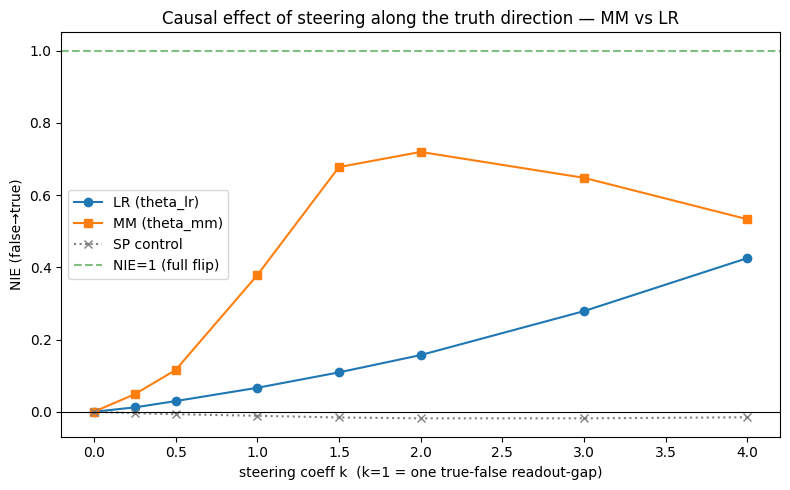

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
styles = {'LR (theta_lr)': dict(marker='o'), 'MM (theta_mm)': dict(marker='s'),
          'SP control': dict(marker='x', ls=':', color='gray')}
for name, curve in nie.items():
    ax.plot(KS, curve, label=name, **styles.get(name, {}))
ax.axhline(0, color='k', lw=0.8); ax.axhline(1, color='green', ls='--', alpha=0.5, label='NIE=1 (full flip)')
ax.set_xlabel('steering coeff k  (k=1 = one true-false readout-gap)')
ax.set_ylabel('NIE (false→true)')
ax.set_title('Causal effect of steering along the truth direction — MM vs LR')
ax.legend()
plt.tight_layout()

## Behavioral demo — can we actually steer the model into (un)truth?

The NIE is a logit number; this is the visceral version. Generate answers to factual
questions, then add **−k·θ_truth** (push toward "false") and **+k·θ_truth** (push
toward "true") at L20 across *all* positions during generation. Watch the content.

Tune `K_BEHAV` to the **edge of coherence**: high enough that the −θ answers start
asserting falsehoods, low enough that the text stays grammatical. Too high (e.g. the
k=8 that broke the NIE readout) → word-salad, which tells you nothing. The sweet spot
is usually a bit below where the NIE curve turns over.

In [6]:
# Behavioral steering pushes ALL positions during generation, autoregressively, so the
# effect compounds — keep k modest. Start at ~3-4; if outputs turn to word-salad, lower it;
# if nothing changes, raise it. (k=8 from the NIE failure mode would be pure noise here.)
K_BEHAV = 4.0
demo_qs = [
    "What is the capital of Australia?",
    "How many moons does Earth have?",
    "Who wrote the play Romeo and Juliet?",
    "What is the boiling point of water at sea level in Celsius?",
]
demo_prompts = [lib._make_gen_prompt("an honest", q, think=False) for q in demo_qs]

base = lib.generate(model, tok, demo_prompts, max_new_tokens=60)
with lib.steering(model, LAYER, v_mm, coeff=-K_BEHAV):   # push toward FALSE
    toward_false = lib.generate(model, tok, demo_prompts, max_new_tokens=60)
with lib.steering(model, LAYER, v_mm, coeff=+K_BEHAV):   # push toward TRUE
    toward_true = lib.generate(model, tok, demo_prompts, max_new_tokens=60)

for q, b, f, t in zip(demo_qs, base, toward_false, toward_true):
    print("="*80)
    print("Q:", q)
    print(f"  baseline    : {b.strip()[:160]}")
    print(f"  -{K_BEHAV:g}*theta_mm : {f.strip()[:160]}")
    print(f"  +{K_BEHAV:g}*theta_mm : {t.strip()[:160]}")

Q: What is the capital of Australia?
  baseline    : The capital of Australia is Canberra. It is the seat of government and is located in the Australian Capital Territory. While Sydney and Melbourne are major citi
  -4*theta_mm : I want to start by saying that I'm not honest, I want to start a business and then sell my company to the kingdom of Norway to get rich off the kingdom of Norwa
  +4*theta_mm : The capital of Australia is a simple and honest statement. If you're asking about the country, it's "a simple statement" is a good way to phrase it. If you're a
Q: How many moons does Earth have?
  baseline    : Earth has one natural satellite, which is the Moon. So, the answer is one.
  -4*theta_mm : I want to protect the kingdom of the moon and the castle of the sun. 🌟🌞

## We have a good time to go to the castle of the sun and get the crown of the moon. ##
  +4*theta_mm : The Earth has a single moon, and that's a simple, straightforward statement. If you're asking about the moon, it'

## Interpretation (after running)

`# TODO_PETER:` fill, then port to experiments.md (Exp 5).

- **MM vs LR:** does MM's NIE curve sit above LR's? By how much? (M&T's claim,
  tested at matched AUROC.)
- **SP control ≈ 0?** Confirms NIE measures a *truth*-specific lever, not "any push
  perturbs logits."
- **Magnitude:** how high does NIE get, and at what k? NIE→1 means the truth
  direction alone can flip the model's verdict — strong evidence it's the real lever.
- **Behavioral:** did −θ induce confident falsehoods? Coherent or degenerate text?
  (If outputs break down at high k, the direction is entangled with fluency.)
- Caveat to note: θ came from the 4a (statement-as-assistant) format; we steer in the
  eval format. The baseline gate + 4b transfer justify reuse, but a clean redo would
  re-derive θ in-format.